In [27]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader

import deep_models.config as c                                       
from deep_models.data import S00MILDataset, load_folds, make_splits  
from deep_models.vqvae import ConvVQVAE
from deep_models.vqvae_train import init_model

from evaluation import (extract_raw_from_loader, flatten_offdiag_bags, pca_bags, plot_embedding_votes,
                        get_device, run_nn_probes, set_device, vq_encode_raw_bags)

In [28]:
device = get_device()   
split_k = 2
num_workers = 4
LATENT_DIM = 64

In [29]:
developamental_folds = load_folds(c.dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1078  val=129  test=146


In [30]:
trainset = S00MILDataset(train_idx, max_instances=150, train=True)
valset = S00MILDataset(val_idx, max_instances=150, train=False)
testset = S00MILDataset(test_idx, max_instances=150, train=False)


loader_kw = dict(batch_size=10, num_workers=num_workers, pin_memory=True)
trainloader = DataLoader(trainset, shuffle=True, **loader_kw)  
valloader = DataLoader(valset, shuffle=False, **loader_kw) 
testloader = DataLoader(testset, shuffle=False, **loader_kw)

In [31]:
raw_tr, y_train = extract_raw_from_loader(trainloader)
raw_va, y_val   = extract_raw_from_loader(valloader)
raw_te, y_test  = extract_raw_from_loader(testloader)

raw_splits = {"train": raw_tr, "val": raw_va, "test": raw_te}

### 1. Baseline: Flattened off-diagonal raw inputs (5 * 17 * 16 = 1360 dims)


In [32]:
bags = {"raw_offdiag": {s: flatten_offdiag_bags(raw_splits[s]) for s in ("train", "val", "test")}}

### 2. Baseline: PCA on flattened off-diagonal raw inputs (64 dims, matching codebooksize)

In [33]:
bags["pca"] = pca_bags(bags["raw_offdiag"], n_components=LATENT_DIM, seed=0)

### 3. Random ConvVQVAE (initialized with init_model, NO training)

In [34]:
torch.manual_seed(0)
vae_rand = ConvVQVAE(latent_channels=16, code_book_size=LATENT_DIM, commitment_cost=0.25, init_channels=16).to(device)
init_model(vae_rand, trainloader)   
vae_rand.eval()

bags["vae_random_zq"] = {s: vq_encode_raw_bags(vae_rand, raw_splits[s])[0] for s in ("train", "val", "test")}

### 4. Trained ConvVQVAE

In [35]:
path = f"best_vqvae_split{split_k}.pt"

torch.manual_seed(0)
vae_trained = ConvVQVAE(latent_channels=16, code_book_size=64, commitment_cost=0.25, init_channels=16).to(device)
state_dict = torch.load(path, map_location=c.device, weights_only=True)
vae_trained.load_state_dict(state_dict)
vae_trained.eval()

bags["vae_trained_zq"] = {s: vq_encode_raw_bags(vae_trained, raw_splits[s])[0] for s in ("train", "val", "test")} #type:ignore

In [36]:
representations = ["raw_offdiag", "pca", "vae_random_zq", "vae_trained_zq"]

In [37]:
rows, artifacts = run_nn_probes(bags=bags,
                                representations=representations,
                                y_train=y_train,
                                y_val=y_val,
                                y_test=y_test,
                                return_artifacts=True,
                                abmil_variants={"ABMIL_linear": None, 
                                                "ABMIL_h64": 64})
df = pd.DataFrame(rows)

[raw_offdiag] LinearBagProbe  val AUC = 0.733  epoch = 27  test AUC = 0.645
[raw_offdiag] LinearInstanceProbeBagLabels_soft  val AUC = 0.773  epoch = 33  test AUC = 0.617
[raw_offdiag] LinearInstanceProbeBagLabels_vote  val AUC = 0.779  epoch = 33  test AUC = 0.621
[raw_offdiag] ABMIL_linear  val AUC = 0.709  epoch = 11  test AUC = 0.630
[raw_offdiag] ABMIL_h64  val AUC = 0.750  epoch = 22  test AUC = 0.646
[pca] LinearBagProbe  val AUC = 0.737  epoch = 2  test AUC = 0.619
[pca] LinearInstanceProbeBagLabels_soft  val AUC = 0.727  epoch = 45  test AUC = 0.510
[pca] LinearInstanceProbeBagLabels_vote  val AUC = 0.724  epoch = 45  test AUC = 0.508
[pca] ABMIL_linear  val AUC = 0.710  epoch = 3  test AUC = 0.606
[pca] ABMIL_h64  val AUC = 0.737  epoch = 12  test AUC = 0.646
[vae_random_zq] LinearBagProbe  val AUC = 0.672  epoch = 9  test AUC = 0.666
[vae_random_zq] LinearInstanceProbeBagLabels_soft  val AUC = 0.706  epoch = 29  test AUC = 0.536
[vae_random_zq] LinearInstanceProbeBagLabels_v

## Visualization in 2-dims

In [38]:
embeddings_2d = {rep: TSNE(n_components=2, init="pca", learning_rate="auto", random_state=0).fit_transform(artifacts[rep]["X_val"]) for rep in representations}

val_sizes = np.array([len(b) for b in bags["vae_trained_zq"]["val"]])
exam_ids = np.repeat(np.arange(len(val_sizes)), val_sizes)
window_labels = np.repeat(y_val, val_sizes)

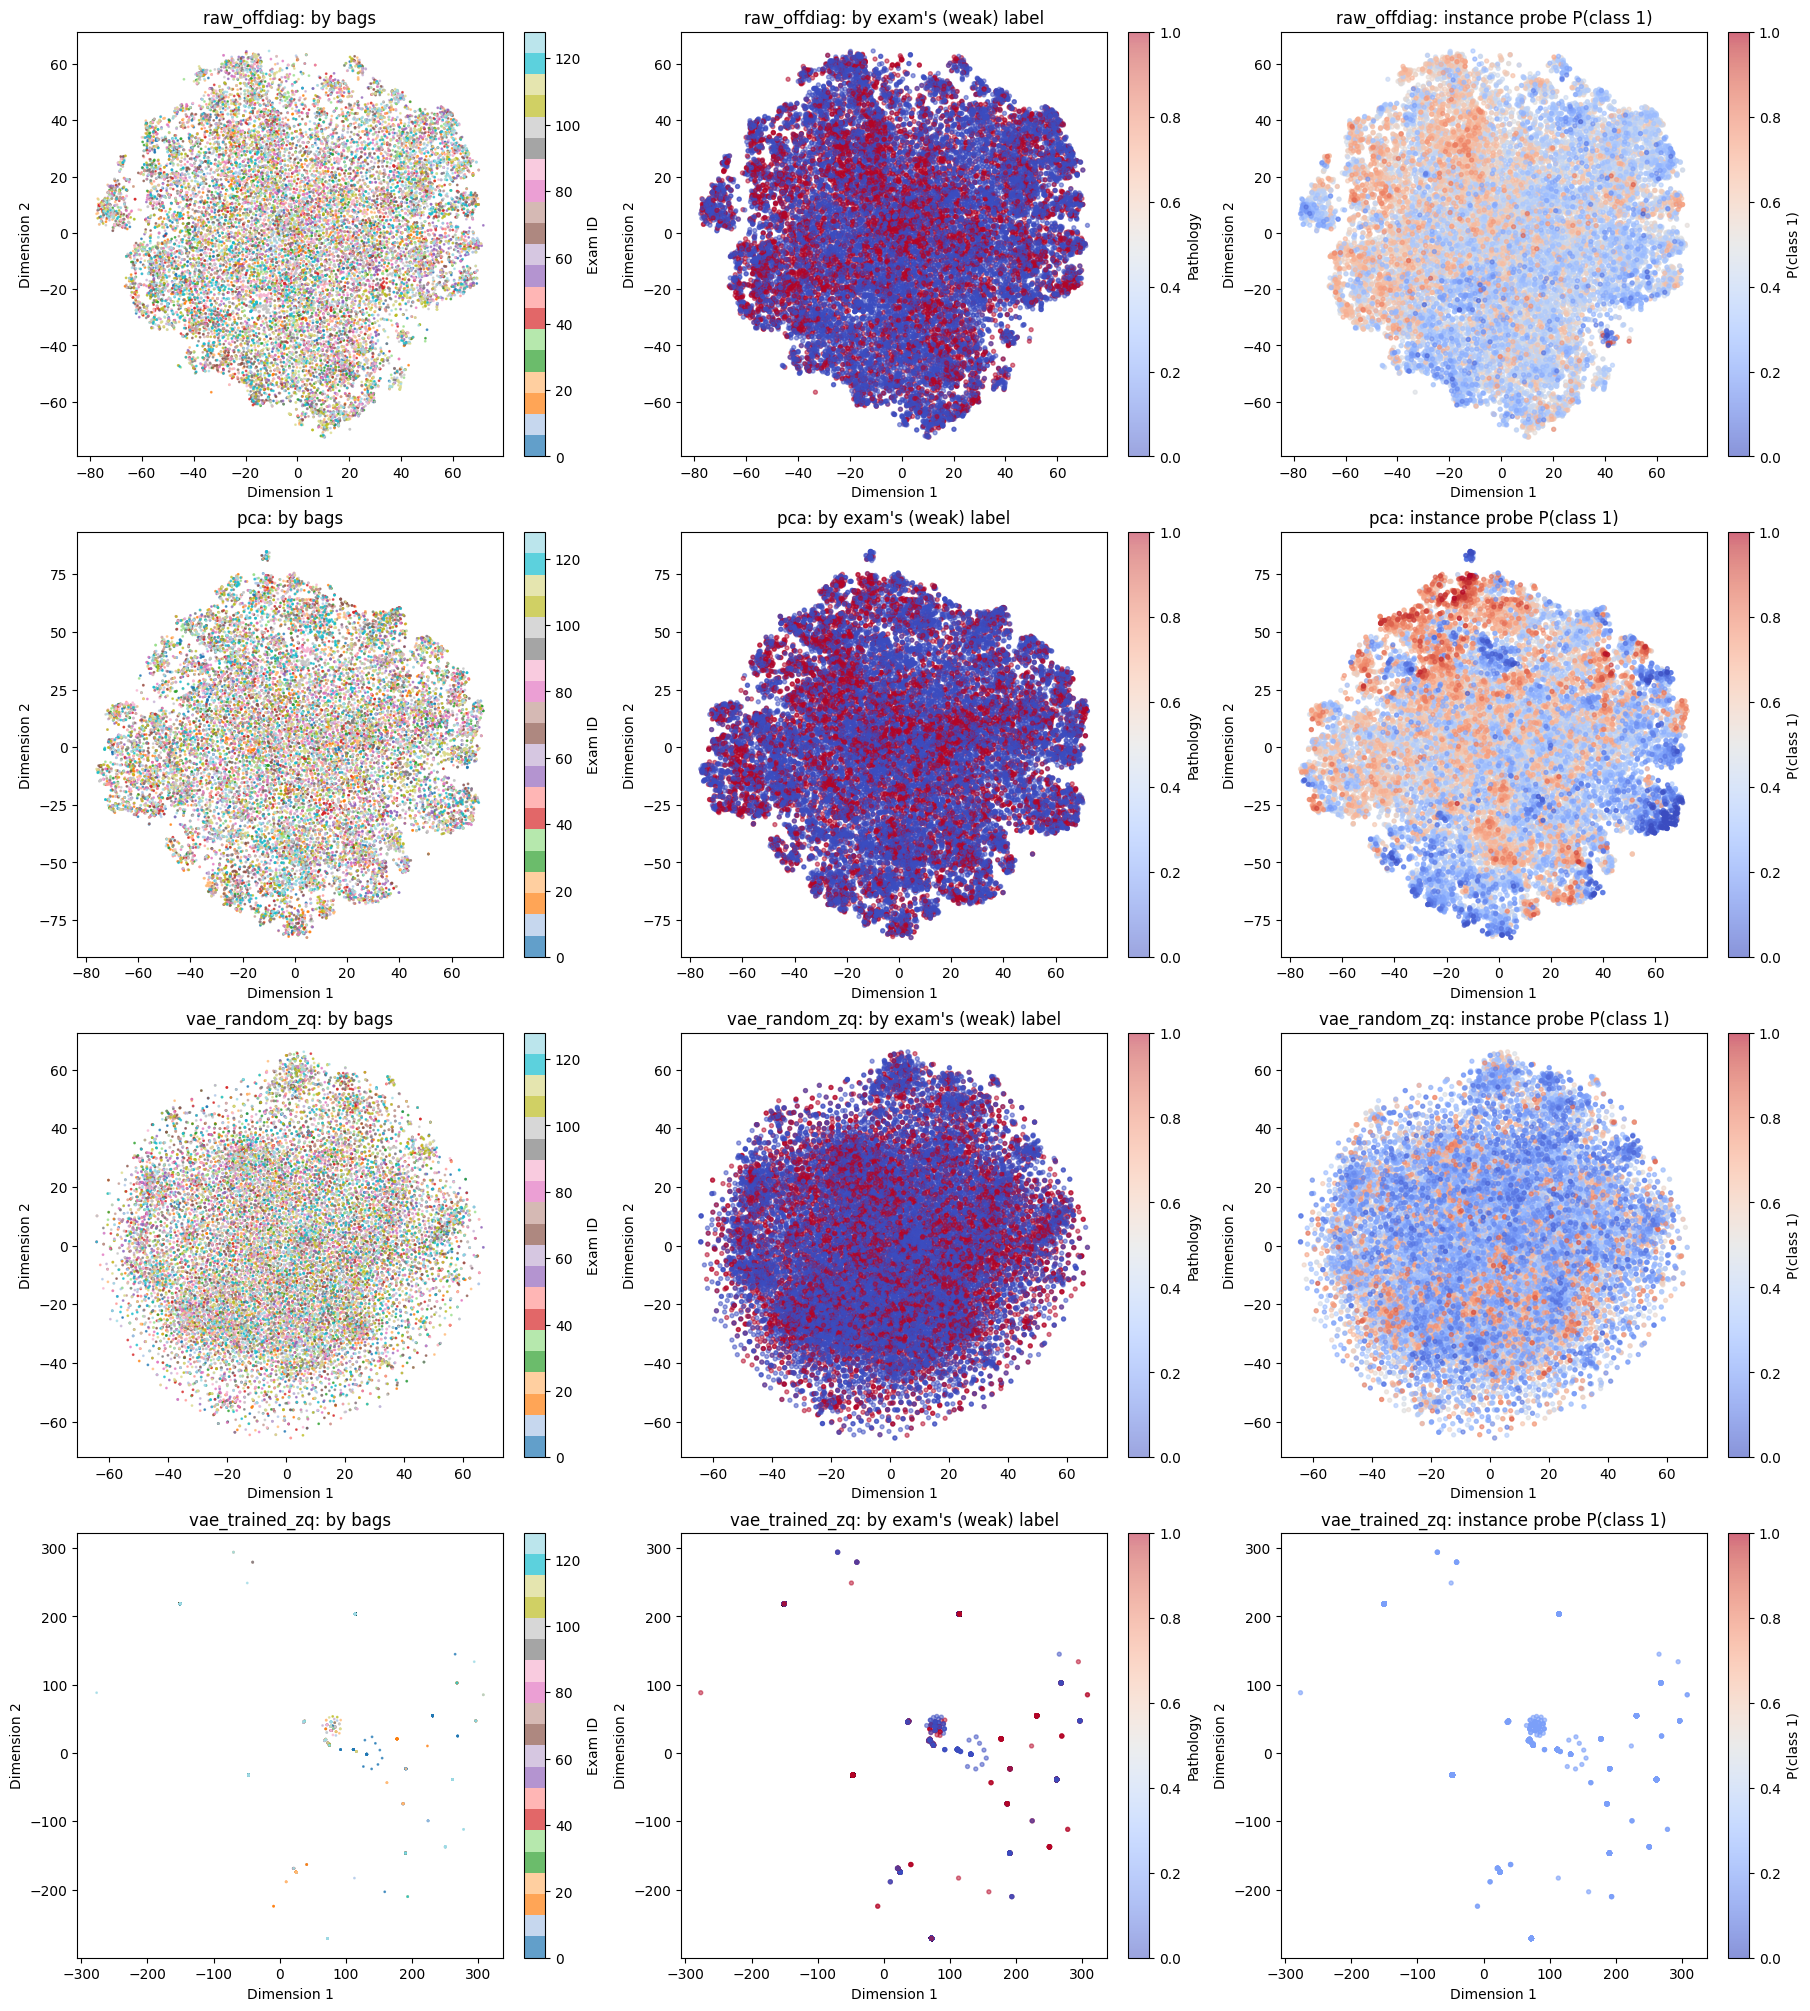

In [39]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="prob")
plt.show()

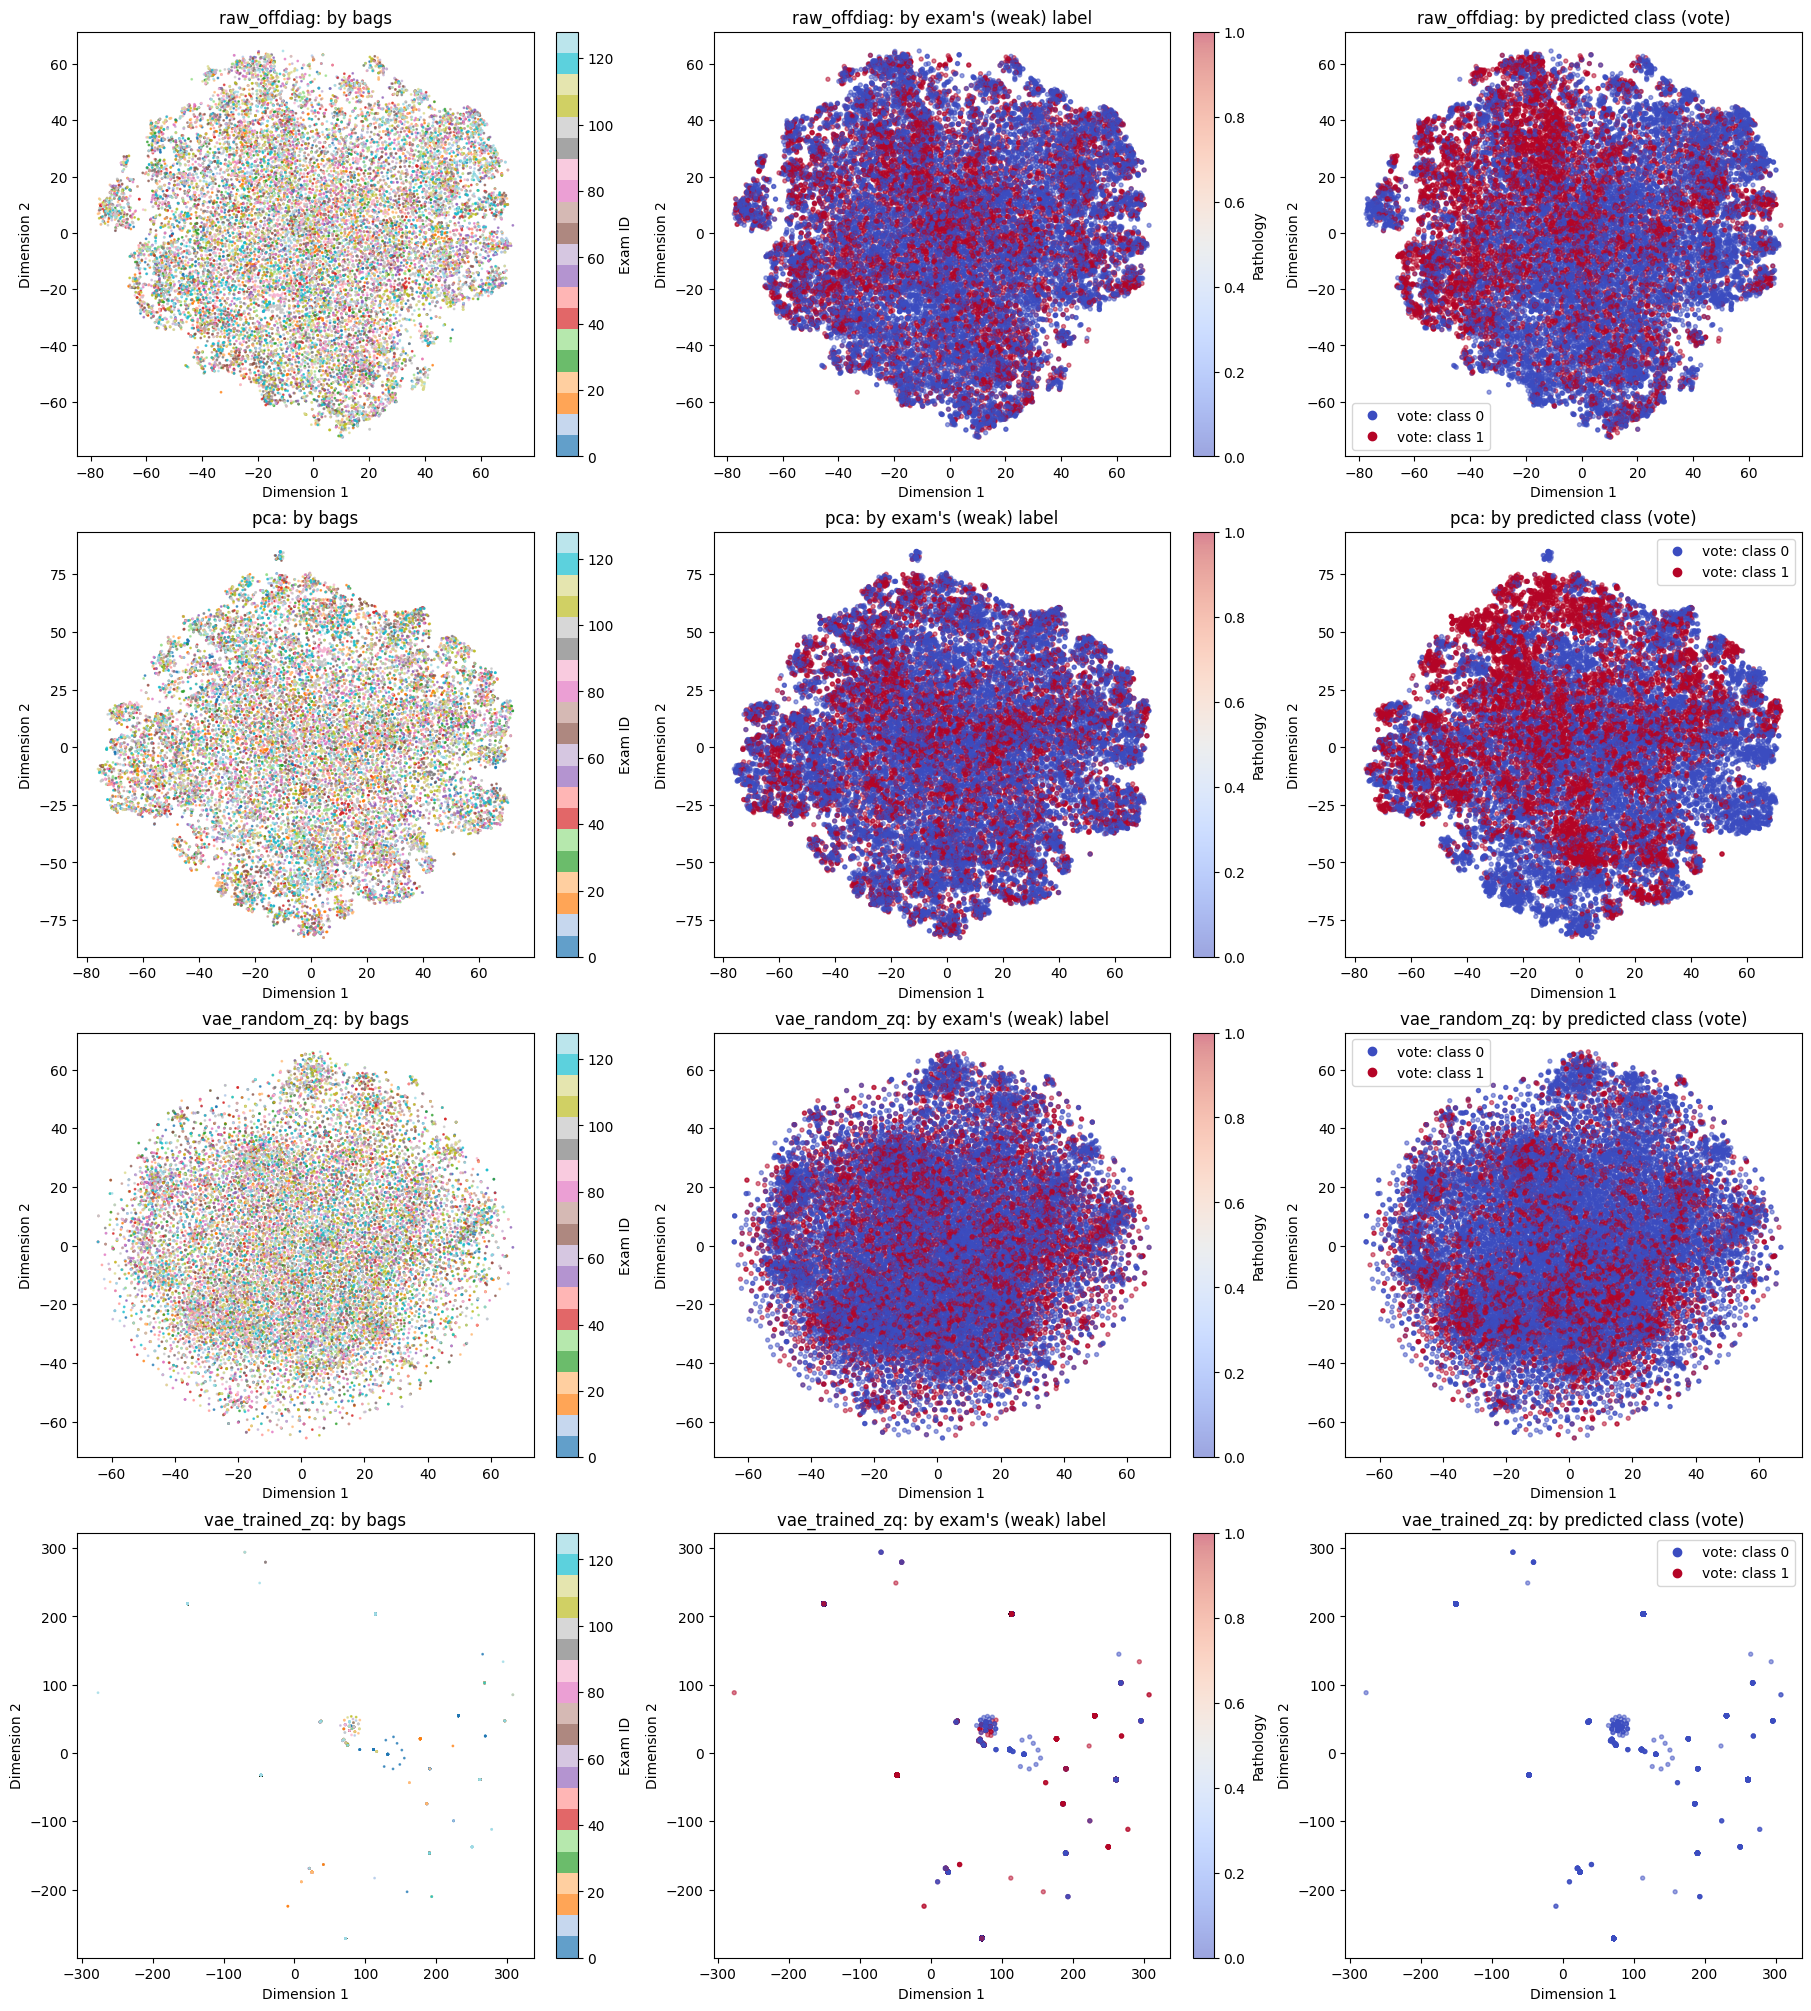

In [40]:
fig, axes = plot_embedding_votes(embeddings=embeddings_2d,
                                 artifacts=artifacts,
                                 exam_ids=exam_ids,
                                 window_labels=window_labels,
                                 rep_of=representations,
                                 mode="vote")
plt.show()